# Inspect the CNN baseline

Read the recorded validation curve and run the actual released image classifier on an infrared observation.

In [1]:
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs/dataset.yaml").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.schema import ROOT, NAMES, MODELS, config


## Training history

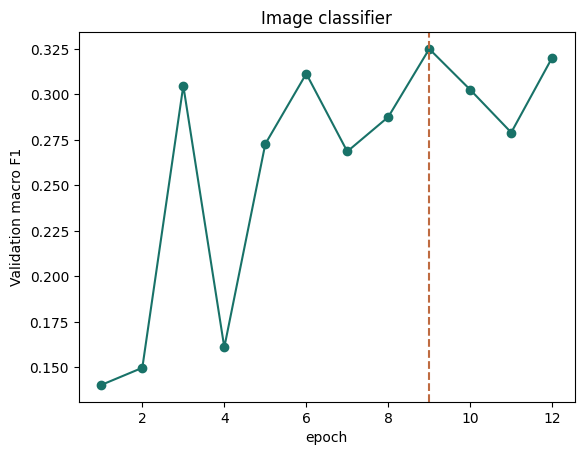

In [2]:
run = json.loads((ROOT/"experiments/cnn/run.json").read_text())
history = pd.DataFrame(run["history"]).set_index("epoch")
ax = history["val_score"].plot(marker="o",color="#187268", ylabel="Validation macro F1",title="Image classifier")
ax.axvline(run["best_epoch"],color="#bf6b41",linestyle="--")
ax.figure

## Class distribution

In [3]:
from src.inference import Registry
from src.schema import IMAGE_NAMES, decode
model = Registry()
file = ROOT/"examples/20170115T0900Z.png"
ir = decode(file.read_bytes(), file.name)
probability, cam, entry = model.predict(ir,"cnn")
pd.DataFrame({"class":IMAGE_NAMES,"probability":probability}).sort_values("probability",ascending=False)

,class,probability
3,Mid-level cloud,0.839537
2,Low cloud,0.112880
1,Very low cloud,0.016618
8,Moderate semitransparent cloud,0.015677
6,Fractional cloud,0.007306
7,Thin semitransparent cloud,0.004704
10,Semitransparent above low or mid cloud,0.001705
4,High opaque cloud,0.001141
9,Thick semitransparent cloud,0.000350
5,Very high opaque cloud,0.000060


## Predicted-class Grad-CAM

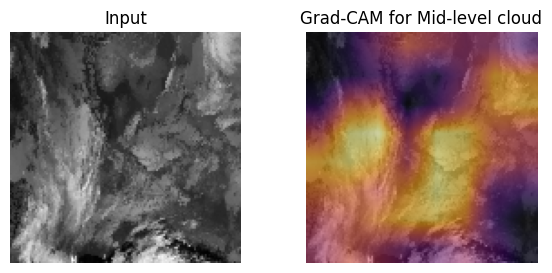

In [4]:
fig, axes = plt.subplots(1,2,figsize=(7,3))
for ax in axes: ax.axis("off"); ax.imshow(ir,cmap="gray_r")
axes[0].set_title("Input")
axes[1].imshow(cam,cmap="inferno",alpha=0.55,vmin=0,vmax=1)
axes[1].set_title("Grad-CAM for " + IMAGE_NAMES[int(probability.argmax())])
fig

## Repeat the baseline training

Run `python -m src.train --workdir reproduction --only cnn --freeze` from the project root to create a separate experiment and checkpoint.